Movie Recommender / Data and EDA

Ratings: 100,836 | Users: 610 | Movies: 9,724
Matrix sparsity: 98.30%
Mean rating: 3.50
Share of ratings >= 4: 48.2%


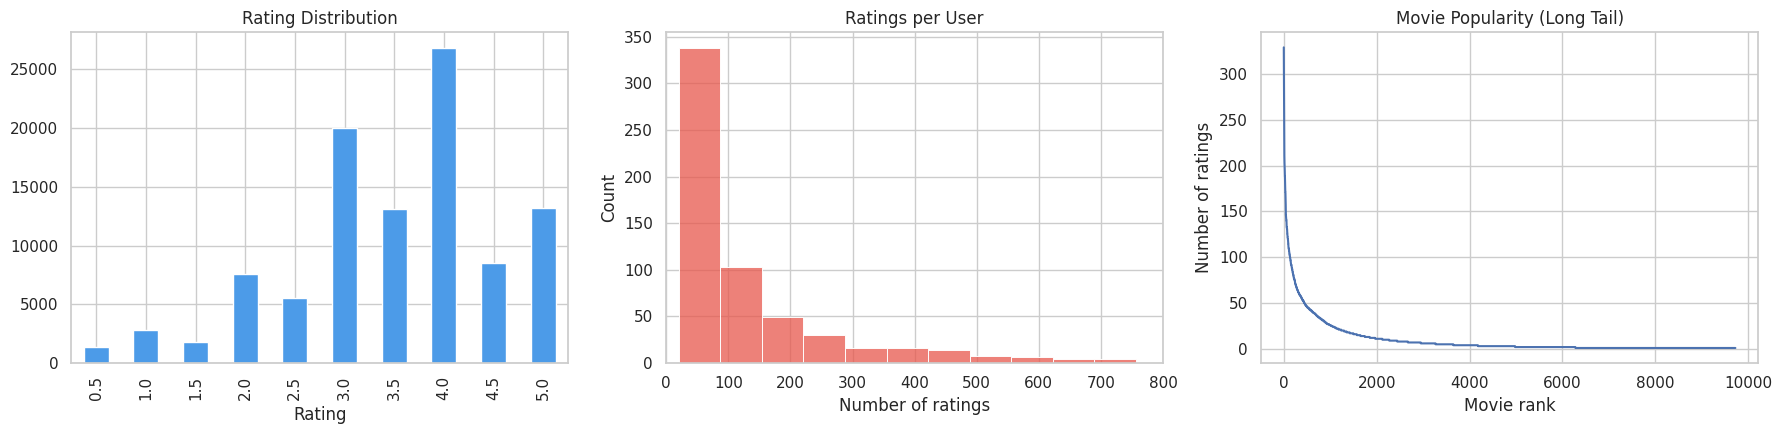

                                    title  n_ratings
                      Forrest Gump (1994)        329
         Shawshank Redemption, The (1994)        317
                      Pulp Fiction (1994)        307
         Silence of the Lambs, The (1991)        279
                       Matrix, The (1999)        278
Star Wars: Episode IV - A New Hope (1977)        251
                     Jurassic Park (1993)        238
                        Braveheart (1995)        237
        Terminator 2: Judgment Day (1991)        224
                  Schindler's List (1993)        220


In [1]:

import pandas as pd, numpy as np
import urllib.request, zipfile
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Download MovieLens small dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
urllib.request.urlretrieve(url, "ml.zip")
zipfile.ZipFile("ml.zip").extractall(".")

ratings = pd.read_csv("ml-latest-small/ratings.csv")
movies = pd.read_csv("ml-latest-small/movies.csv")

n_users = ratings.userId.nunique()
n_items = ratings.movieId.nunique()
sparsity = 1 - len(ratings) / (n_users * n_items)
print(f"Ratings: {len(ratings):,} | Users: {n_users} | Movies: {n_items:,}")
print(f"Matrix sparsity: {sparsity:.2%}")
print(f"Mean rating: {ratings.rating.mean():.2f}")
print(f"Share of ratings >= 4: {(ratings.rating >= 4).mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Rating distribution
ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0], color="#4C9BE8")
axes[0].set_title("Rating Distribution")
axes[0].set_xlabel("Rating")

# 2) Ratings per user
sns.histplot(ratings.groupby("userId").size(), bins=40, ax=axes[1], color="#E8574C")
axes[1].set_title("Ratings per User")
axes[1].set_xlabel("Number of ratings")
axes[1].set_xlim(0, 800)

# 3) Long tail of movie popularity
pop = ratings.groupby("movieId").size().sort_values(ascending=False).values
axes[2].plot(pop)
axes[2].set_title("Movie Popularity (Long Tail)")
axes[2].set_xlabel("Movie rank")
axes[2].set_ylabel("Number of ratings")

plt.tight_layout()
plt.show()

top10 = (ratings.groupby("movieId").size().sort_values(ascending=False).head(10)
         .rename("n_ratings").reset_index().merge(movies, on="movieId"))
print(top10[["title", "n_ratings"]].to_string(index=False))

 Movie Recommender/ Models and Evaluation

Train: 80,419 | Test: 20,417
                   Precision@10  Recall@10  NDCG@10  HitRate@10  Coverage
Popularity               0.0615     0.0496   0.0800      0.3260    0.0093
Item-KNN (cosine)        0.0885     0.0831   0.1098      0.4595    0.0563
SVD (50 factors)         0.0834     0.0888   0.1107      0.4696    0.0607


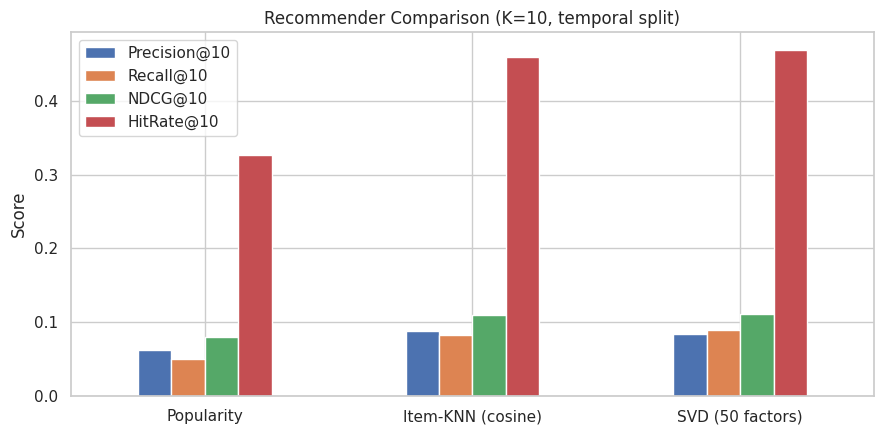

In [ ]:

from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# 1) Temporal split: last 20% of each user's ratings go to test
r = ratings.sort_values(["userId", "timestamp"]).copy()
r["rank_from_end"] = r.groupby("userId").cumcount(ascending=False)
n_per_user = r.groupby("userId")["rating"].transform("size")
r["is_test"] = r["rank_from_end"] < np.ceil(n_per_user * 0.2)

uids, iids = r.userId.unique(), r.movieId.unique()
u2i = {u: i for i, u in enumerate(uids)}
m2i = {m: i for i, m in enumerate(iids)}
r["u"] = r.userId.map(u2i)
r["i"] = r.movieId.map(m2i)
nU, nI = len(uids), len(iids)

train, test = r[~r.is_test], r[r.is_test]
print(f"Train: {len(train):,} | Test: {len(test):,}")

# Matrices: positives (rating >= 4) for learning, all train ratings for 'already seen'
pos = train[train.rating >= 4]
R_pos = csr_matrix((np.ones(len(pos)), (pos.u, pos.i)), shape=(nU, nI))
R_seen = csr_matrix((np.ones(len(train)), (train.u, train.i)), shape=(nU, nI))

# Ground truth: movies each user liked (rating >= 4) in the test period
relevant = test[test.rating >= 4].groupby("u")["i"].apply(set).to_dict()

# 2) Score matrices (users x items)
# a) Popularity baseline
item_pop = np.asarray(R_pos.sum(axis=0)).ravel()
scores_pop = np.tile(item_pop, (nU, 1)).astype(np.float32)

# b) Item-based collaborative filtering (cosine similarity)
Rn = normalize(R_pos, axis=0)
S = (Rn.T @ Rn).toarray().astype(np.float32)
np.fill_diagonal(S, 0)
scores_knn = np.asarray(R_pos @ S, dtype=np.float32)

# c) SVD matrix factorization
svd = TruncatedSVD(n_components=50, random_state=42)
Z = svd.fit_transform(R_pos)
scores_svd = (Z @ svd.components_).astype(np.float32)

# 3) Evaluation
def evaluate(scores, K=10):
    scores = scores.copy()
    scores[R_seen.nonzero()] = -np.inf          # never recommend already-seen movies
    top = np.argpartition(-scores, K, axis=1)[:, :K]
    order = np.take_along_axis(scores, top, 1).argsort(1)[:, ::-1]
    top = np.take_along_axis(top, order, 1)
    disc = 1 / np.log2(np.arange(2, K + 2))

    P, Rc, N, H = [], [], [], []
    for u in range(nU):
        rel = relevant.get(u)
        if not rel:
            continue
        hits = np.array([i in rel for i in top[u]])
        P.append(hits.mean())
        Rc.append(hits.sum() / len(rel))
        H.append(hits.any())
        N.append((hits * disc).sum() / disc[:min(len(rel), K)].sum())
    return {
        f"Precision@{K}": np.mean(P), f"Recall@{K}": np.mean(Rc),
        f"NDCG@{K}": np.mean(N), f"HitRate@{K}": np.mean(H),
        "Coverage": len(np.unique(top)) / nI,
    }

results = pd.DataFrame({
    "Popularity": evaluate(scores_pop),
    "Item-KNN (cosine)": evaluate(scores_knn),
    "SVD (50 factors)": evaluate(scores_svd),
}).T.round(4)
print(results.to_string())

results[["Precision@10", "Recall@10", "NDCG@10", "HitRate@10"]].plot.bar(
    figsize=(9, 4.5), rot=0)
plt.title("Recommender Comparison (K=10, temporal split)")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

Movie Recommender/Models and Evaluation

Train: 80,419 | Test: 20,417
                   Precision@10  Recall@10  NDCG@10  HitRate@10  Coverage
Popularity               0.0615     0.0496   0.0800      0.3260    0.0093
Item-KNN (cosine)        0.0885     0.0831   0.1098      0.4595    0.0563
SVD (50 factors)         0.0834     0.0888   0.1107      0.4696    0.0607


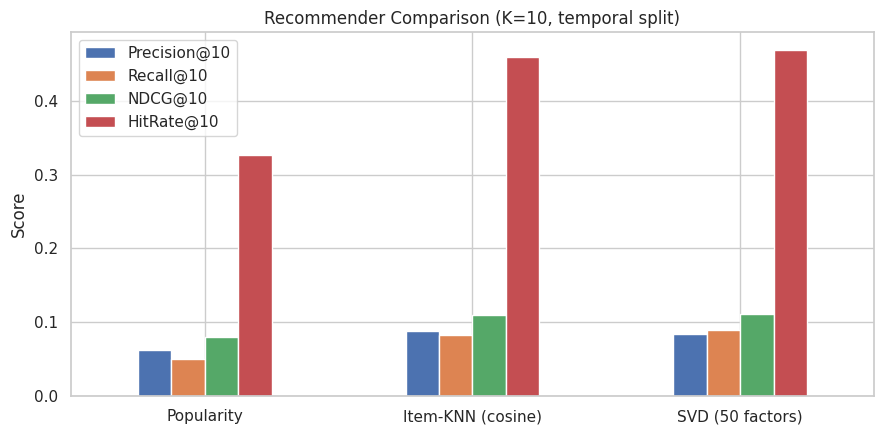

In [ ]:

from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# 1) Temporal split: last 20% of each user's ratings go to test
r = ratings.sort_values(["userId", "timestamp"]).copy()
r["rank_from_end"] = r.groupby("userId").cumcount(ascending=False)
n_per_user = r.groupby("userId")["rating"].transform("size")
r["is_test"] = r["rank_from_end"] < np.ceil(n_per_user * 0.2)

uids, iids = r.userId.unique(), r.movieId.unique()
u2i = {u: i for i, u in enumerate(uids)}
m2i = {m: i for i, m in enumerate(iids)}
r["u"] = r.userId.map(u2i)
r["i"] = r.movieId.map(m2i)
nU, nI = len(uids), len(iids)

train, test = r[~r.is_test], r[r.is_test]
print(f"Train: {len(train):,} | Test: {len(test):,}")

# Matrices: positives (rating >= 4) for learning, all train ratings for 'already seen'
pos = train[train.rating >= 4]
R_pos = csr_matrix((np.ones(len(pos)), (pos.u, pos.i)), shape=(nU, nI))
R_seen = csr_matrix((np.ones(len(train)), (train.u, train.i)), shape=(nU, nI))

# Ground truth: movies each user liked (rating >= 4) in the test period
relevant = test[test.rating >= 4].groupby("u")["i"].apply(set).to_dict()

# 2) Score matrices (users x items)
# a) Popularity baseline
item_pop = np.asarray(R_pos.sum(axis=0)).ravel()
scores_pop = np.tile(item_pop, (nU, 1)).astype(np.float32)

# b) Item-based collaborative filtering (cosine similarity)
Rn = normalize(R_pos, axis=0)
S = (Rn.T @ Rn).toarray().astype(np.float32)
np.fill_diagonal(S, 0)
scores_knn = np.asarray(R_pos @ S, dtype=np.float32)

# c) SVD matrix factorization
svd = TruncatedSVD(n_components=50, random_state=42)
Z = svd.fit_transform(R_pos)
scores_svd = (Z @ svd.components_).astype(np.float32)

# 3) Evaluation
def evaluate(scores, K=10):
    scores = scores.copy()
    scores[R_seen.nonzero()] = -np.inf          # never recommend already-seen movies
    top = np.argpartition(-scores, K, axis=1)[:, :K]
    order = np.take_along_axis(scores, top, 1).argsort(1)[:, ::-1]
    top = np.take_along_axis(top, order, 1)
    disc = 1 / np.log2(np.arange(2, K + 2))

    P, Rc, N, H = [], [], [], []
    for u in range(nU):
        rel = relevant.get(u)
        if not rel:
            continue
        hits = np.array([i in rel for i in top[u]])
        P.append(hits.mean())
        Rc.append(hits.sum() / len(rel))
        H.append(hits.any())
        N.append((hits * disc).sum() / disc[:min(len(rel), K)].sum())
    return {
        f"Precision@{K}": np.mean(P), f"Recall@{K}": np.mean(Rc),
        f"NDCG@{K}": np.mean(N), f"HitRate@{K}": np.mean(H),
        "Coverage": len(np.unique(top)) / nI,
    }

results = pd.DataFrame({
    "Popularity": evaluate(scores_pop),
    "Item-KNN (cosine)": evaluate(scores_knn),
    "SVD (50 factors)": evaluate(scores_svd),
}).T.round(4)
print(results.to_string())

results[["Precision@10", "Recall@10", "NDCG@10", "HitRate@10"]].plot.bar(
    figsize=(9, 4.5), rot=0)
plt.title("Recommender Comparison (K=10, temporal split)")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

Movie Recommender/ Models and Evaluation

Train: 80,419 | Test: 20,417
                   Precision@10  Recall@10  NDCG@10  HitRate@10  Coverage
Popularity               0.0615     0.0496   0.0800      0.3260    0.0093
Item-KNN (cosine)        0.0885     0.0831   0.1098      0.4595    0.0563
SVD (50 factors)         0.0834     0.0888   0.1107      0.4696    0.0607


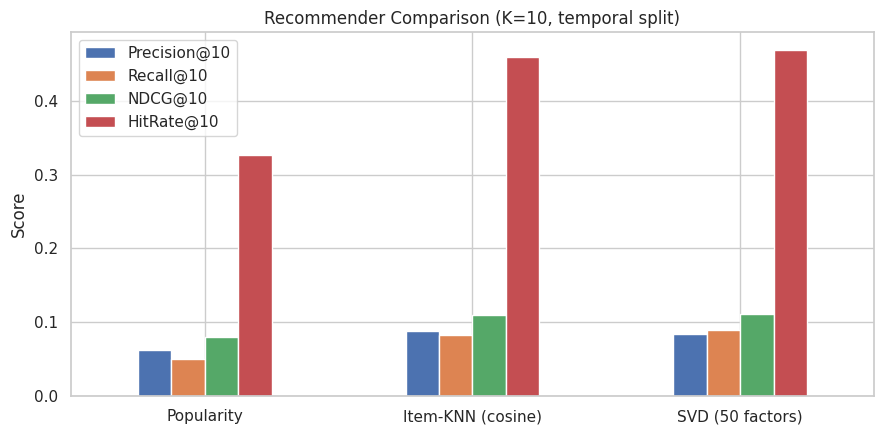

In [2]:

from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# 1) Temporal split: last 20% of each user's ratings go to test
r = ratings.sort_values(["userId", "timestamp"]).copy()
r["rank_from_end"] = r.groupby("userId").cumcount(ascending=False)
n_per_user = r.groupby("userId")["rating"].transform("size")
r["is_test"] = r["rank_from_end"] < np.ceil(n_per_user * 0.2)

uids, iids = r.userId.unique(), r.movieId.unique()
u2i = {u: i for i, u in enumerate(uids)}
m2i = {m: i for i, m in enumerate(iids)}
r["u"] = r.userId.map(u2i)
r["i"] = r.movieId.map(m2i)
nU, nI = len(uids), len(iids)

train, test = r[~r.is_test], r[r.is_test]
print(f"Train: {len(train):,} | Test: {len(test):,}")

# Matrices: positives (rating >= 4) for learning, all train ratings for 'already seen'
pos = train[train.rating >= 4]
R_pos = csr_matrix((np.ones(len(pos)), (pos.u, pos.i)), shape=(nU, nI))
R_seen = csr_matrix((np.ones(len(train)), (train.u, train.i)), shape=(nU, nI))

# Ground truth: movies each user liked (rating >= 4) in the test period
relevant = test[test.rating >= 4].groupby("u")["i"].apply(set).to_dict()

# 2) Score matrices (users x items)
# a) Popularity baseline
item_pop = np.asarray(R_pos.sum(axis=0)).ravel()
scores_pop = np.tile(item_pop, (nU, 1)).astype(np.float32)

# b) Item-based collaborative filtering (cosine similarity)
Rn = normalize(R_pos, axis=0)
S = (Rn.T @ Rn).toarray().astype(np.float32)
np.fill_diagonal(S, 0)
scores_knn = np.asarray(R_pos @ S, dtype=np.float32)

# c) SVD matrix factorization
svd = TruncatedSVD(n_components=50, random_state=42)
Z = svd.fit_transform(R_pos)
scores_svd = (Z @ svd.components_).astype(np.float32)

# 3) Evaluation
def evaluate(scores, K=10):
    scores = scores.copy()
    scores[R_seen.nonzero()] = -np.inf          # never recommend already-seen movies
    top = np.argpartition(-scores, K, axis=1)[:, :K]
    order = np.take_along_axis(scores, top, 1).argsort(1)[:, ::-1]
    top = np.take_along_axis(top, order, 1)
    disc = 1 / np.log2(np.arange(2, K + 2))

    P, Rc, N, H = [], [], [], []
    for u in range(nU):
        rel = relevant.get(u)
        if not rel:
            continue
        hits = np.array([i in rel for i in top[u]])
        P.append(hits.mean())
        Rc.append(hits.sum() / len(rel))
        H.append(hits.any())
        N.append((hits * disc).sum() / disc[:min(len(rel), K)].sum())
    return {
        f"Precision@{K}": np.mean(P), f"Recall@{K}": np.mean(Rc),
        f"NDCG@{K}": np.mean(N), f"HitRate@{K}": np.mean(H),
        "Coverage": len(np.unique(top)) / nI,
    }

results = pd.DataFrame({
    "Popularity": evaluate(scores_pop),
    "Item-KNN (cosine)": evaluate(scores_knn),
    "SVD (50 factors)": evaluate(scores_svd),
}).T.round(4)
print(results.to_string())

results[["Precision@10", "Recall@10", "NDCG@10", "HitRate@10"]].plot.bar(
    figsize=(9, 4.5), rot=0)
plt.title("Recommender Comparison (K=10, temporal split)")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

 Movie Recommender /Demo, Popularity Bias, Cold Start

User 1 liked (examples from training data):
  - Star Wars: Episode VI - Return of the Jedi (1983)
  - Dumb & Dumber (Dumb and Dumber) (1994)
  - Bambi (1942)
  - Bottle Rocket (1996)
  - Gladiator (2000)
  - American Beauty (1999)
  - Dogma (1999)
  - Billy Madison (1995)

Top 10 recommendations: Popularity
   1. Shawshank Redemption, The (1994)
   2. Silence of the Lambs, The (1991)
   3. Fight Club (1999)
   4. Schindler's List (1993)
   5. Godfather, The (1972)
   6. Lord of the Rings: The Fellowship of the Ring, The (2001)
   7. Lord of the Rings: The Return of the King, The (2003)
   8. Terminator 2: Judgment Day (1991)
   9. Lord of the Rings: The Two Towers, The (2002)
  10. Seven (a.k.a. Se7en) (1995)

Top 10 recommendations: Item-KNN (cosine)
   1. Groundhog Day (1993)
   2. Terminator, The (1984)
   3. Ferris Bueller's Day Off (1986)
   4. Die Hard (1988)
   5. Godfather, The (1972)
   6. Back to the Future (1985)
   7. Ghostbusters (a.k.a. Ghost Busters) (1984)
   8. Godfath

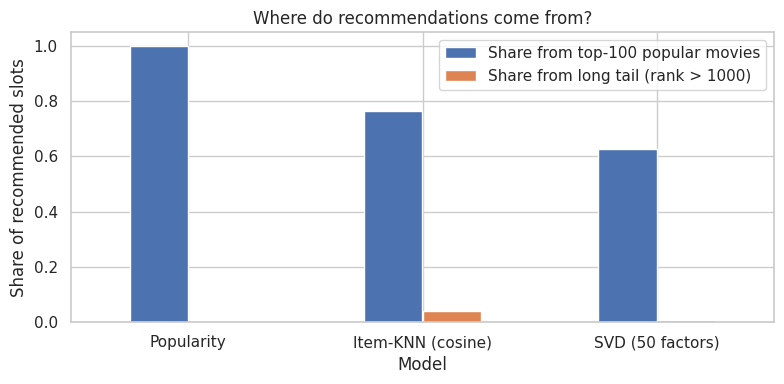


New user, no history (popularity fallback):
  - Shawshank Redemption, The (1994)
  - Forrest Gump (1994)
  - Pulp Fiction (1994)
  - Matrix, The (1999)
  - Silence of the Lambs, The (1991)
  - Star Wars: Episode IV - A New Hope (1977)
  - Fight Club (1999)
  - Braveheart (1995)
  - Star Wars: Episode V - The Empire Strikes Back (1980)
  - Schindler's List (1993)

New user who says they like 'Toy Story' and 'Matrix, The':
  - Star Wars: Episode IV - A New Hope (1977)
  - Star Wars: Episode V - The Empire Strikes Back (1980)
  - Saving Private Ryan (1998)
  - Sixth Sense, The (1999)
  - Star Wars: Episode VI - Return of the Jedi (1983)
  - Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
  - Pulp Fiction (1994)
  - Fight Club (1999)
  - Forrest Gump (1994)
  - American Beauty (1999)


In [3]:

title_of = movies.set_index("movieId")["title"]
all_scores = {
    "Popularity": scores_pop,
    "Item-KNN (cosine)": scores_knn,
    "SVD (50 factors)": scores_svd,
}

def top_k(scores, K=10):
    s = scores.copy()
    s[R_seen.nonzero()] = -np.inf
    top = np.argpartition(-s, K, axis=1)[:, :K]
    order = np.take_along_axis(s, top, 1).argsort(1)[:, ::-1]
    return np.take_along_axis(top, order, 1)

# ---- 1) Demo for one user ----
demo_user = 1   # change to any userId from 1 to 610
u = u2i[demo_user]

liked = (train[(train.u == u) & (train.rating >= 4)]
         .sort_values("rating", ascending=False).head(8))
print(f"User {demo_user} liked (examples from training data):")
for m in liked.movieId:
    print("  -", title_of[m])

for name, sc in all_scores.items():
    s = sc[u].copy()
    s[R_seen[u].nonzero()[1]] = -np.inf
    top = np.argsort(-s)[:10]
    print(f"\nTop 10 recommendations: {name}")
    for rank, i in enumerate(top, 1):
        print(f"  {rank:2d}. {title_of[iids[i]]}")

# ---- 2) Popularity bias ----
pop_rank = np.empty(nI, dtype=int)
pop_rank[np.argsort(-item_pop)] = np.arange(nI)    # 0 = most popular

rows = []
for name, sc in all_scores.items():
    top = top_k(sc)
    ranks = pop_rank[top]
    rows.append({
        "Model": name,
        "Share from top-100 popular movies": (ranks < 100).mean(),
        "Share from long tail (rank > 1000)": (ranks > 1000).mean(),
        "Median popularity rank": np.median(ranks),
    })
bias = pd.DataFrame(rows).set_index("Model").round(3)
print("\nPopularity bias analysis")
print(bias.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
bias[["Share from top-100 popular movies",
      "Share from long tail (rank > 1000)"]].plot.bar(ax=ax, rot=0)
ax.set_title("Where do recommendations come from?")
ax.set_ylabel("Share of recommended slots")
plt.tight_layout()
plt.show()

# ---- 3) Cold start: brand-new user with no history ----
def recommend_new_user(liked_titles_keywords=None, K=10):
    """No history -> fall back to popularity. If the user names a few liked
    movies, use item-similarity (Item-KNN) from those seeds."""
    if not liked_titles_keywords:
        return [title_of[iids[i]] for i in np.argsort(-item_pop)[:K]]
    seeds = []
    for kw in liked_titles_keywords:
        match = movies[movies.title.str.contains(kw, case=False, regex=False)]
        match = match[match.movieId.isin(m2i)]
        if len(match):
            seeds.append(m2i[match.iloc[0].movieId])
    if not seeds:
        return recommend_new_user(None, K)
    s = S[seeds].sum(axis=0)
    s[seeds] = -np.inf
    return [title_of[iids[i]] for i in np.argsort(-s)[:K]]

print("\nNew user, no history (popularity fallback):")
for t in recommend_new_user():
    print("  -", t)

print("\nNew user who says they like 'Toy Story' and 'Matrix, The':")
for t in recommend_new_user(["Toy Story (1995)", "Matrix, The"]):
    print("  -", t)

Movie Recommender/ Popularity-Penalty Re-ranking

                 Precision@10  Recall@10  NDCG@10  HitRate@10  Coverage  Top100 share  Long-tail share
Model    lambda                                                                                       
Item-KNN 0.00          0.0885     0.0831   0.1098      0.4595    0.0563        0.7621           0.0393
         0.25          0.0802     0.0805   0.1028      0.4375    0.0795        0.6311           0.1098
         0.50          0.0652     0.0761   0.0858      0.4003    0.1032        0.4574           0.2598
         0.75          0.0424     0.0651   0.0611      0.2889    0.1220        0.2892           0.4748
         1.00          0.0257     0.0472   0.0400      0.1824    0.1288        0.1346           0.7241
         1.50          0.0056     0.0114   0.0090      0.0439    0.1241        0.0126           0.9707
         2.00          0.0024     0.0041   0.0029      0.0186    0.1219        0.0000           0.9985
         3.00          0.0020     0.0033   0.0029      0.0152    0.1684  

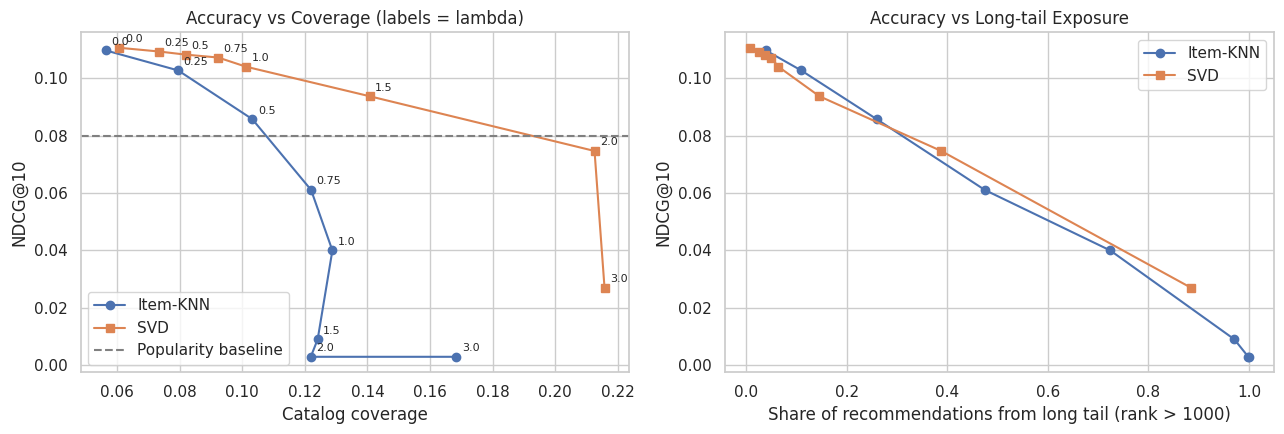

In [4]:

def zscore_rows(M):
    return (M - M.mean(axis=1, keepdims=True)) / (M.std(axis=1, keepdims=True) + 1e-9)

log_pop = np.log1p(item_pop)
pop_z = ((log_pop - log_pop.mean()) / log_pop.std()).astype(np.float32)

def rerank(scores, lam):
    return zscore_rows(scores) - lam * pop_z[None, :]

lambdas = [0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
rows = []
for name, base in [("Item-KNN", scores_knn), ("SVD", scores_svd)]:
    for lam in lambdas:
        sc = rerank(base, lam)
        res = evaluate(sc)
        ranks = pop_rank[top_k(sc)]
        res["Model"] = name
        res["lambda"] = lam
        res["Top100 share"] = (ranks < 100).mean()
        res["Long-tail share"] = (ranks > 1000).mean()
        rows.append(res)

tradeoff = pd.DataFrame(rows).set_index(["Model", "lambda"]).round(4)
print(tradeoff[["Precision@10", "Recall@10", "NDCG@10", "HitRate@10",
                "Coverage", "Top100 share", "Long-tail share"]].to_string())

# Trade-off plots: accuracy vs diversity
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, marker in [("Item-KNN", "o"), ("SVD", "s")]:
    d = tradeoff.loc[name]
    axes[0].plot(d["Coverage"], d["NDCG@10"], marker=marker, label=name)
    axes[1].plot(d["Long-tail share"], d["NDCG@10"], marker=marker, label=name)
    for lam, rw in d.iterrows():
        axes[0].annotate(str(lam), (rw["Coverage"], rw["NDCG@10"]),
                         textcoords="offset points", xytext=(4, 4), fontsize=8)
axes[0].axhline(results.loc["Popularity", "NDCG@10"], color="gray", ls="--",
                label="Popularity baseline")
axes[0].set_xlabel("Catalog coverage")
axes[0].set_ylabel("NDCG@10")
axes[0].set_title("Accuracy vs Coverage (labels = lambda)")
axes[0].legend()
axes[1].set_xlabel("Share of recommendations from long tail (rank > 1000)")
axes[1].set_ylabel("NDCG@10")
axes[1].set_title("Accuracy vs Long-tail Exposure")
axes[1].legend()
plt.tight_layout()
plt.show()

Improved Cold Start with popularity penalty

In [5]:

def recommend_new_user_v2(seed_keywords, K=10, lam=1.0):
    seeds = []
    for kw in seed_keywords:
        match = movies[movies.title.str.contains(kw, case=False, regex=False)]
        match = match[match.movieId.isin(m2i)]
        if len(match):
            seeds.append(m2i[match.iloc[0].movieId])
    if not seeds:
        return [title_of[iids[i]] for i in np.argsort(-item_pop)[:K]]
    s = S[seeds].mean(axis=0)
    s = (s - s.mean()) / (s.std() + 1e-9) - lam * pop_z
    s[seeds] = -np.inf
    return [title_of[iids[i]] for i in np.argsort(-s)[:K]]

for lam in [0, 1.0, 2.0]:
    print(f"\nSeeds: Toy Story + Matrix | lambda = {lam}")
    for t in recommend_new_user_v2(["Toy Story (1995)", "Matrix, The"], lam=lam):
        print("  -", t)


Seeds: Toy Story + Matrix | lambda = 0
  - Star Wars: Episode IV - A New Hope (1977)
  - Star Wars: Episode V - The Empire Strikes Back (1980)
  - Saving Private Ryan (1998)
  - Sixth Sense, The (1999)
  - Star Wars: Episode VI - Return of the Jedi (1983)
  - Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
  - Pulp Fiction (1994)
  - Fight Club (1999)
  - Forrest Gump (1994)
  - American Beauty (1999)

Seeds: Toy Story + Matrix | lambda = 1.0
  - Saving Private Ryan (1998)
  - Star Wars: Episode V - The Empire Strikes Back (1980)
  - Sixth Sense, The (1999)
  - Star Wars: Episode IV - A New Hope (1977)
  - Star Wars: Episode VI - Return of the Jedi (1983)
  - Terminator, The (1984)
  - Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
  - Toy Story 2 (1999)
  - Die Hard (1988)
  - Shrek (2001)

Seeds: Toy Story + Matrix | lambda = 2.0
  - Hatchet II (2010)
  - Digging Up the Marrow (2014)
  - Stingray Sam (2009)
  - ABCs of D